# Experiment No. 8 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Cleaning and Preparation  
**Problem Statement:** Analyzing Customer Churn in a Telecommunications Company  
**Dataset:** `"Telecom_Customer_Churn.csv"`  

**Tasks to Perform:**
1. Import the "Telecom_Customer_Churn.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Handle missing values in the dataset, deciding on an appropriate strategy.
4. Remove any duplicate records from the dataset.
5. Check for inconsistent data, such as inconsistent formatting or spelling variations, and standardize it.
6. Convert columns to the correct data types as needed.
7. Identify and handle outliers in the data.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2 - Tasks 1 & 2: Import and Explore the Dataset
# Load Telecom_Customer_Churn.csv with URL fallback
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv("Telecom_Customer_Churn.csv")
except Exception:
    df = pd.read_csv(url)

print("Dataset Shape (Rows, Columns):", df.shape)
print("\nFirst 5 rows of Telecom Churn dataset:")
display(df.head()) if 'display' in globals() else print(df.head())

print("\nDataset Structure (Data Types and Non-Null Counts):")
df.info()

print("\nInitial Descriptive Statistics:")
display(df.describe()) if 'display' in globals() else print(df.describe())

Dataset Shape (Rows, Columns): (7043, 21)

First 5 rows of Telecom Churn dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...  

In [3]:
# Cell 3 - Task 6: Convert Columns to Correct Data Types
# 'TotalCharges' contains blank spaces (' ') and is read as 'object'; convert to numeric
print("Data type of TotalCharges before conversion:", df['TotalCharges'].dtype)

# Coerce errors so invalid strings become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Data type of TotalCharges after conversion :", df['TotalCharges'].dtype)

Data type of TotalCharges before conversion: str
Data type of TotalCharges after conversion : float64


In [4]:
# Cell 4 - Task 3: Handle Missing Values
# Check for missing values in all columns
missing_series = df.isnull().sum()
print("Columns with missing values:")
print(missing_series[missing_series > 0])

# Strategy: Inspect rows with missing TotalCharges
print("\nSample rows where TotalCharges is NaN (Notice tenure = 0 for new customers):")
display(df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']].head())

# Appropriate Strategy: Since these are new customers with tenure = 0, TotalCharges is imputed as 0.0
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

print("\nVerification after handling missing values:")
print("Total null values in dataset:", df.isnull().sum().sum())

Columns with missing values:
TotalCharges    11
dtype: int64

Sample rows where TotalCharges is NaN (Notice tenure = 0 for new customers):


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN



Verification after handling missing values:
Total null values in dataset: 0


In [5]:
# Cell 5 - Task 4: Remove Duplicate Records
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {num_duplicates}")

# Remove duplicate records
df = df.drop_duplicates()
print(f"Dataset shape after removing duplicates: {df.shape}")

Number of duplicate rows found: 0
Dataset shape after removing duplicates: (7043, 21)


In [6]:
# Cell 6 - Task 5: Check and Standardize Inconsistent Data
# 1. Strip leading and trailing whitespace from string columns
str_cols = df.select_dtypes(include='object').columns
for col in str_cols:
    df[col] = df[col].str.strip()

# 2. Standardize redundant category values:
# 'No internet service' and 'No phone service' represent 'No' for that specific feature
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df[col] = df[col].replace({'No internet service': 'No'})

df['MultipleLines'] = df['MultipleLines'].replace({'No phone service': 'No'})

# 3. Standardize SeniorCitizen from 0/1 to 'No'/'Yes' for consistency
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print("Standardized Categories Verification:")
print("OnlineSecurity unique values:", df['OnlineSecurity'].unique())
print("MultipleLines  unique values:", df['MultipleLines'].unique())
print("SeniorCitizen  unique values:", df['SeniorCitizen'].unique())

Standardized Categories Verification:
OnlineSecurity unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines  unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
SeniorCitizen  unique values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


C:\Users\bsais\AppData\Local\Temp\ipykernel_7444\2976809919.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  str_cols = df.select_dtypes(include='object').columns


--- Outlier Detection using Interquartile Range (IQR) ---
tenure          | Q1:    9.00 | Q3:   55.00 | IQR:   46.00 | Outliers: 0
MonthlyCharges  | Q1:   35.50 | Q3:   89.85 | IQR:   54.35 | Outliers: 0
TotalCharges    | Q1:  398.55 | Q3: 3786.60 | IQR: 3388.05 | Outliers: 0


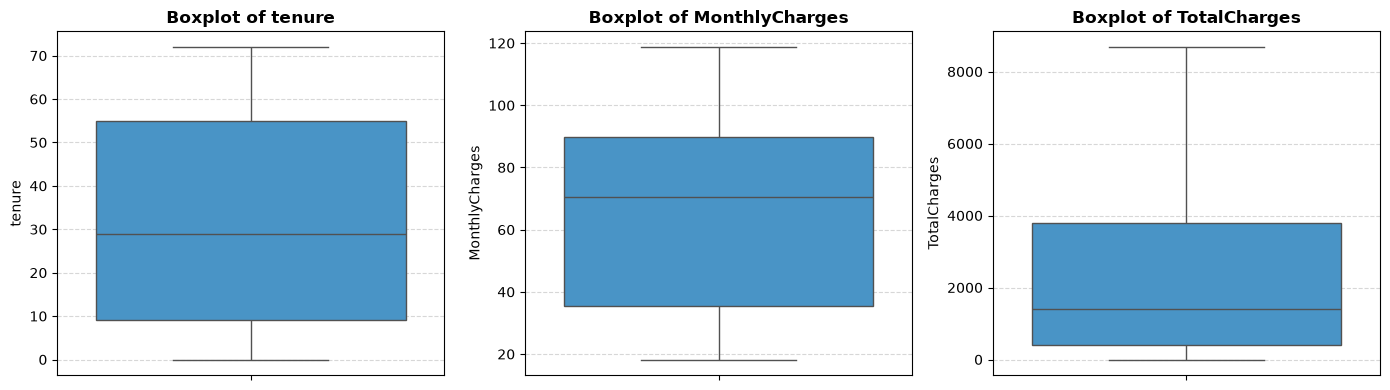

In [7]:
# Cell 7 - Task 7: Identify and Handle Outliers
# Numerical columns to check for outliers
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("--- Outlier Detection using Interquartile Range (IQR) ---")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col:15s} | Q1: {Q1:7.2f} | Q3: {Q3:7.2f} | IQR: {IQR:7.2f} | Outliers: {len(outliers)}")

# Visualizing distributions using Boxplots
plt.figure(figsize=(14, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col], color='#3498db')
    plt.title(f'Boxplot of {col}', fontweight='bold')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

       CLEANED & PREPARED DATASET SUMMARY
Total Records : 7043
Total Columns : 21
Missing Values: 0
Duplicate Rows: 0


C:\Users\bsais\AppData\Local\Temp\ipykernel_7444\1431654598.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])


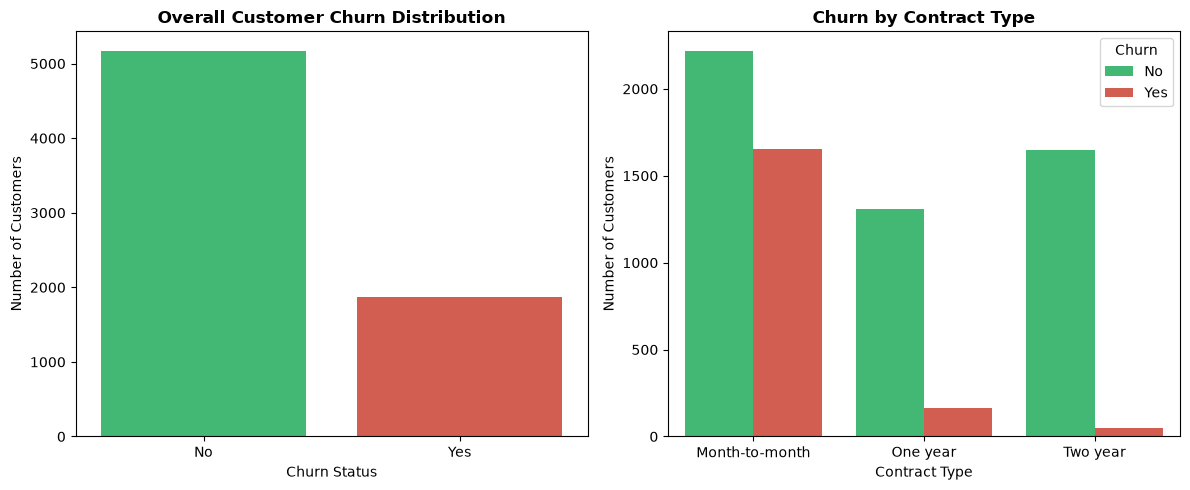


Churn Percentage:
Churn
No     73.46%
Yes    26.54%
Name: proportion, dtype: str


In [8]:
# Cell 8 - Final Summary & Customer Churn Insights
print("=" * 50)
print("       CLEANED & PREPARED DATASET SUMMARY")
print("=" * 50)
print(f"Total Records : {df.shape[0]}")
print(f"Total Columns : {df.shape[1]}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print("=" * 50)

# Customer Churn Insights Visualization
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Overall Customer Churn Distribution', fontweight='bold')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Contract Type', fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

print("\nChurn Percentage:")
print((df['Churn'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')